In [1]:
!pip install polars

In [3]:
import gc
from datetime import timedelta

import numpy as np
import polars as pl
import lightgbm as lgb

Загрузчик датафрейма

In [4]:
STREAMING = True


def collect_df(lf: pl.LazyFrame) -> pl.DataFrame:
    """Аккуратный collect, чтобы можно было легко отключить streaming."""
    return lf.collect(engine="streaming" if STREAMING else "in-memory")

## 1. Настройки

In [5]:
PATH = "data/train.parquet"  # замените на путь к данным

HORIZON = 30  # горизонт прогноза, дней

# Окна для признаков: последние N дней
WINDOWS = [1, 3, 7, 14, 32, 45, 60, 90]

# Окна, для которых считаем средний чек / GMV на заказ
RATIO_WINDOWS = [32, 90]

# Колонки, по которым строим агрегаты
AGG_COLS = [
    "gmv",
    "gmv_search",
    "gmv_cat",
    "to_cart",
    "to_ord",
    "searches",
    "search_to_cart",
    "search_to_ord",
    "cat_to_cart",
    "cat_to_ord",
    "has_search_to_cart",
    "has_search_to_ord",
    "has_cat_to_cart",
    "has_cat_to_ord",
]

MAX_HISTORY_DAYS = max(WINDOWS)

# Сколько снапшотов использовать для обучения. Чем меньше, тем меньше памяти, но меньше данных для модели.
N_TRAIN_SNAPSHOTS = 33  # 33 max

# Шаг между обучающими снапшотами. 7 дней — больше данных, но больше памяти. 14 дней — хороший компромисс.
SNAPSHOT_STEP_DAYS = 7

SEED = 42

## 2. Ленивый датафрейм

In [6]:
lf = (
    pl.scan_parquet(PATH)
    .select(["event_date", "user_id", *AGG_COLS])
    .with_columns([pl.col("event_date").cast(pl.Date)] + [pl.col(c).fill_null(0) for c in AGG_COLS])
)

## 3. Получение крайних дат

In [7]:
bounds = (
    lf.select(
        pl.col("event_date").min().alias("min_date"),
        pl.col("event_date").max().alias("max_date"),
    )
    .pipe(collect_df)
)

min_date = bounds["min_date"][0]
max_date = bounds["max_date"][0]

print("min_date:", min_date)
print("max_date:", max_date)

min_date: 2025-01-01
max_date: 2026-02-13


## 4. Получение списка уникальных пользователей

In [8]:
users = (
    lf.select("user_id")
    .unique()
    .pipe(collect_df)
)

n_users = users.height
print("n_users:", n_users)

n_users: 250000


## 5. Создание набора дат для снапшотов

In [9]:
test_snapshot = max_date - timedelta(days=HORIZON)
valid_snapshot = test_snapshot - timedelta(days=HORIZON)

train_start = min_date + timedelta(days=MAX_HISTORY_DAYS)
train_end = valid_snapshot - timedelta(days=HORIZON)

if train_end < train_start:
    raise ValueError("Недостаточно истории для обучения.")

train_snapshots = (
    pl.date_range(
        start=train_start,
        end=train_end,
        interval=f"{SNAPSHOT_STEP_DAYS}d",
        eager=True,
    )
    .to_list()
)

print("train snapshots cout:", len(train_snapshots))
# Берём последние N_TRAIN_SNAPSHOTS, чтобы не раздувать память
train_snapshots = train_snapshots[-N_TRAIN_SNAPSHOTS:]

print("test_snapshot:", test_snapshot)
print("valid_snapshot:", valid_snapshot)
print("train_snapshots:", train_snapshots)

train snapshots cout: 33
test_snapshot: 2026-01-14
valid_snapshot: 2025-12-15
train_snapshots: [datetime.date(2025, 4, 1), datetime.date(2025, 4, 8), datetime.date(2025, 4, 15), datetime.date(2025, 4, 22), datetime.date(2025, 4, 29), datetime.date(2025, 5, 6), datetime.date(2025, 5, 13), datetime.date(2025, 5, 20), datetime.date(2025, 5, 27), datetime.date(2025, 6, 3), datetime.date(2025, 6, 10), datetime.date(2025, 6, 17), datetime.date(2025, 6, 24), datetime.date(2025, 7, 1), datetime.date(2025, 7, 8), datetime.date(2025, 7, 15), datetime.date(2025, 7, 22), datetime.date(2025, 7, 29), datetime.date(2025, 8, 5), datetime.date(2025, 8, 12), datetime.date(2025, 8, 19), datetime.date(2025, 8, 26), datetime.date(2025, 9, 2), datetime.date(2025, 9, 9), datetime.date(2025, 9, 16), datetime.date(2025, 9, 23), datetime.date(2025, 9, 30), datetime.date(2025, 10, 7), datetime.date(2025, 10, 14), datetime.date(2025, 10, 21), datetime.date(2025, 10, 28), datetime.date(2025, 11, 4), datetime.date(

## 6. Список колонок (без их расчета)

In [10]:
# суммарные значения базовых колонок за W дней (группа 1)
sum_base_feature_cols = [
    f"{col}_sum_{w}d"
    for col in AGG_COLS
    for w in WINDOWS
]

# число дней с gmv > 0 за W дней (группа 2)
active_feature_cols = [
    f"active_days_{w}d"
    for w in WINDOWS
]

# суммарный GVM, деленный на число заказов за W дней (группа 3)
ratio_feature_cols = [
    f"gmv_per_order_{w}d"
    for w in RATIO_WINDOWS
]

# объединение колонок
feature_cols = (
    sum_base_feature_cols
    + active_feature_cols
    + ["days_since_last_purchase"]  # число дней с последней покупки
    + ratio_feature_cols
)

# вручную созданные признаки (создаются в make_snapshot) из колонок, указанных выше (группа 4)
extra_feature_cols = [
    # тренды (сравнение короткого и длинного периода - ускорение/замедление) (группа 4.1)
    "gmv_trend_7_vs_32",
    "gmv_trend_32_vs_90",
    "orders_trend_7_vs_32",
    "carts_trend_7_vs_32",
    # доля заказов от корзины (конверсия из корзины в заказ) (группа 4.2)
    "cart_to_order_rate_32",
    "cart_to_order_rate_90",
    # средний GMV на день с покупкой за W дней (группа 4.3)
    "gmv_per_active_day_32",
    "gmv_per_active_day_90",
    # среднее число заказов на день с покупкой за 32 дня (группа 4.4)
    "orders_per_active_day_32",
    # доли отдельных источников GMV в общем GMV за 28 дня (группа 4.5)
    "gmv_search_share_32",
    "gmv_cat_share_32",
    # конверсия в корзину (группа 4.6)
    "search_to_cart_rate_32",
    "cat_to_cart_rate_32",
    # конверсия в заказ (группа 4.7)
    "search_to_ord_rate_32",
    "cat_to_ord_rate_32",
]

# итоговый набор признаков, которые пойдут в модель
feature_cols += extra_feature_cols

# список колонок, которые будут дозаполнены нулями
fill_cols = sum_base_feature_cols + active_feature_cols

print("n_features:", len(feature_cols))

n_features: 138


## 7. Функция создания снапшотов (среза данных для обучения или теста)

In [19]:
def make_snapshot(snapshot_date):
    """
    Строит признаки для всех пользователей на дату snapshot_date.

    Target:
        sum(gmv) за следующие HORIZON дней после snapshot_date.

    Features:
        агрегаты за последние WINDOWS дней до snapshot_date включительно.
    """
    # переменные - границы дат
    snap_lit = pl.lit(snapshot_date)
    hist_start_lit = pl.lit(snapshot_date - timedelta(days=MAX_HISTORY_DAYS))
    future_end_lit = pl.lit(snapshot_date + timedelta(days=HORIZON))

    # Берём только нужный диапазон: история + будущее для таргета
    snap_lf = lf.filter(
        (pl.col("event_date") > hist_start_lit)
        & (pl.col("event_date") <= future_end_lit)
    )

    hist_lf = snap_lf.filter(pl.col("event_date") <= snap_lit)
    future_lf = snap_lf.filter(pl.col("event_date") > snap_lit)

    # выражения для group_by().agg()
    agg_exprs = []

    # Суммы за последние w дней для каждой колонки (группа 1)
    for col in AGG_COLS:
        for w in WINDOWS:
            start_lit = pl.lit(snapshot_date - timedelta(days=w))
            agg_exprs.append(
                pl.col(col)
                .filter(pl.col("event_date") > start_lit)
                .sum()
                .alias(f"{col}_sum_{w}d")
            )

    # Число активных дней с gmv > 0 (группа 2)
    for w in WINDOWS:
        start_lit = pl.lit(snapshot_date - timedelta(days=w))
        agg_exprs.append(
            pl.col("event_date")
            .filter((pl.col("event_date") > start_lit) & (pl.col("gmv") > 0))
            .n_unique()
            .alias(f"active_days_{w}d")
        )

    # затухающий GVM
    for half_life in [7, 14, 30]:
        decay_col = f"gmv_decay_hl{half_life}"
        agg_exprs.append(
            (
                pl.col("gmv")
                * (0.5 ** ((snap_lit - pl.col("event_date")).dt.total_days() / half_life))
            ).sum().alias(decay_col)
        )

    # Дата последней покупки
    agg_exprs.append(
        pl.col("event_date")
        .filter(pl.col("gmv") > 0)
        .max()
        .alias("last_purchase_date")
    )

    # Дополнительные lifetime-признаки
    agg_exprs.extend([
        # дата первой активности в доступной истории
        pl.col("event_date").min().alias("first_activity_date"),
        # дата первой покупки в доступной истории
        pl.col("event_date").filter(pl.col("gmv") > 0).min().alias("first_purchase_date"),
        # суммарный GMV за доступную историю
        pl.col("gmv").sum().alias("lifetime_gmv"),
        # суммарное число заказов за доступную историю
        pl.col("to_ord").sum().alias("lifetime_orders"),
        # число дней с покупками за доступную историю
        pl.col("event_date").filter(pl.col("gmv") > 0).count().alias("total_purchase_days"),
    ])

    # выполнение агрегации
    hist_feat = hist_lf.group_by("user_id").agg(agg_exprs)
    # таргет GMV за следующие 30 дней
    target_feat = future_lf.group_by("user_id").agg(pl.col("gmv").sum().alias("target_30d"))


    # создание выходного датасета
    out = (
        users.lazy()
        # присоединение признаков и таргета ко всем пользователям
        .join(hist_feat, on="user_id", how="left")
        .join(target_feat, on="user_id", how="left")
        # заполнение нулями для неактивных пользователей
        .with_columns(pl.col(fill_cols).fill_null(0))
        # число дней с последней покупки
        .with_columns(
            (snap_lit - pl.col("last_purchase_date"))
            .dt.total_days()
            .alias("days_since_last_purchase")
        )
        .drop("last_purchase_date")
        .with_columns(pl.col("days_since_last_purchase").fill_null(999))

        .with_columns([
            # тренды (группа 4.1)
            (pl.col("gmv_sum_7d") / ((pl.col("gmv_sum_32d") / 4) + 1))
            .alias("gmv_trend_7_vs_32"),

            (pl.col("gmv_sum_32d") / ((pl.col("gmv_sum_90d") / 3) + 1))
            .alias("gmv_trend_32_vs_90"),

            (pl.col("to_ord_sum_7d") / ((pl.col("to_ord_sum_32d") / 4) + 1))
            .alias("orders_trend_7_vs_32"),

            (pl.col("to_cart_sum_7d") / ((pl.col("to_cart_sum_32d") / 4) + 1))
            .alias("carts_trend_7_vs_32"),

            # Конверсия из корзины в заказ (группа 4.2)
            (pl.col("to_ord_sum_32d") / pl.col("to_cart_sum_32d").clip(lower_bound=1))
            .alias("cart_to_order_rate_32"),

            (pl.col("to_ord_sum_90d") / pl.col("to_cart_sum_90d").clip(lower_bound=1))
            .alias("cart_to_order_rate_90"),

            # средний GMV на день с покупкой за W дней (группа 4.3)
            (pl.col("gmv_sum_32d") / pl.col("active_days_32d").clip(lower_bound=1))
            .alias("gmv_per_active_day_32"),

            (pl.col("gmv_sum_90d") / pl.col("active_days_90d").clip(lower_bound=1))
            .alias("gmv_per_active_day_90"),

            # среднее число заказов на день с покупкой за 32 дня (группа 4.4)
            (pl.col("to_ord_sum_32d") / pl.col("active_days_32d").clip(lower_bound=1))
            .alias("orders_per_active_day_32"),

            # доли отдельных источников GMV в общем GMV за 32 дня (группа 4.5)
            (pl.col("gmv_search_sum_32d") / pl.col("gmv_sum_32d").clip(lower_bound=1e-6))
            .alias("gmv_search_share_32"),

            (pl.col("gmv_cat_sum_32d") / pl.col("gmv_sum_32d").clip(lower_bound=1e-6))
            .alias("gmv_cat_share_32"),
        ])
        .with_columns([
            # конверсия в корзину (группа 4.6)
            (pl.col("search_to_cart_sum_32d") / pl.col("searches_sum_32d").clip(lower_bound=1))
            .alias("search_to_cart_rate_32"),

            (pl.col("cat_to_cart_sum_32d") / pl.col("active_days_32d").clip(lower_bound=1))
            .alias("cat_to_cart_rate_32"),

            # конверсия в заказ (группа 4.7)
            (pl.col("search_to_ord_sum_32d") / pl.col("searches_sum_32d").clip(lower_bound=1))
            .alias("search_to_ord_rate_32"),

            (pl.col("cat_to_ord_sum_32d") / pl.col("active_days_32d").clip(lower_bound=1))
            .alias("cat_to_ord_rate_32"),
        ])
        # суммарный GVM, деленный на число заказов за W дней (группа 3)
        .with_columns([
                (pl.col(f"gmv_sum_{w}d") / pl.col(f"to_ord_sum_{w}d").clip(lower_bound=1))
                .alias(f"gmv_per_order_{w}d")
                for w in RATIO_WINDOWS
        ])
        # таргет
        .with_columns(pl.col("target_30d").fill_null(0))
        .with_columns(pl.col(feature_cols + ["target_30d"]).cast(pl.Float32))
        # срез только нужных колонок
        .select(["user_id", *feature_cols, "target_30d"])
    )

    return collect_df(out)

## 8. Формирование тренировочных срезов

In [20]:
n_features = len(feature_cols)
n_train = len(train_snapshots)

estimated_mb = n_train * n_users * n_features * 4 / (1024 ** 2)
print(f"Estimated X_train size: {estimated_mb:.1f} MB")

X_train = np.empty(
    (n_train * n_users, n_features),
    dtype=np.float32,
)

y_train = np.empty(
    n_train * n_users,
    dtype=np.float32,
)

for i, snap in enumerate(train_snapshots):
    print(f"Processing train snapshot: {snap}")

    df_snap = make_snapshot(snap)

    if df_snap.height != n_users:
        raise ValueError(
            f"Snapshot {snap}: expected {n_users} rows, got {df_snap.height}"
        )

    start = i * n_users
    end = start + n_users

    X_train[start:end, :] = df_snap.select(feature_cols).to_numpy()
    y_train[start:end] = df_snap.get_column("target_30d").to_numpy()

    del df_snap
    gc.collect()

Estimated X_train size: 4343.0 MB
Processing train snapshot: 2025-04-01
Processing train snapshot: 2025-04-08
Processing train snapshot: 2025-04-15
Processing train snapshot: 2025-04-22
Processing train snapshot: 2025-04-29
Processing train snapshot: 2025-05-06
Processing train snapshot: 2025-05-13
Processing train snapshot: 2025-05-20
Processing train snapshot: 2025-05-27
Processing train snapshot: 2025-06-03
Processing train snapshot: 2025-06-10
Processing train snapshot: 2025-06-17
Processing train snapshot: 2025-06-24
Processing train snapshot: 2025-07-01
Processing train snapshot: 2025-07-08
Processing train snapshot: 2025-07-15
Processing train snapshot: 2025-07-22
Processing train snapshot: 2025-07-29
Processing train snapshot: 2025-08-05
Processing train snapshot: 2025-08-12
Processing train snapshot: 2025-08-19
Processing train snapshot: 2025-08-26
Processing train snapshot: 2025-09-02
Processing train snapshot: 2025-09-09
Processing train snapshot: 2025-09-16
Processing train

## 9. Формирование контрольных срезов

In [21]:
if valid_snapshot is not None:
    print("Processing valid snapshot:", valid_snapshot)

    valid_df = make_snapshot(valid_snapshot)

    if valid_df.height != n_users:
        raise ValueError(
            f"Valid snapshot: expected {n_users} rows, got {valid_df.height}"
        )

    X_valid = valid_df.select(feature_cols).to_numpy()
    y_valid = valid_df.get_column("target_30d").to_numpy()

    del valid_df
    gc.collect()

else:
    X_valid = None
    y_valid = None

Processing valid snapshot: 2025-12-15


## 10. Логарифмирование

In [22]:
np.log1p(y_train, out=y_train)

if y_valid is not None:
    np.log1p(y_valid, out=y_valid)

## 11. Обучение модели

In [23]:
params = {
    "objective": "regression",
    "metric": "none",
    "learning_rate": 0.05,
    "num_leaves": 127,
    "max_bin": 127,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 5,
    "min_child_samples": 200,
    "lambda_l2": 1.0,
    "verbosity": -1,
    "seed": SEED,
}

dtrain = lgb.Dataset(
    X_train,
    label=y_train,
    feature_name=feature_cols,
    free_raw_data=True,
)

valid_sets = [dtrain]
callbacks = [lgb.log_evaluation(100)]

if X_valid is not None:
    dvalid = lgb.Dataset(
        X_valid,
        label=y_valid,
        reference=dtrain,
        free_raw_data=True,
    )
    valid_sets.append(dvalid)
    callbacks.append(lgb.early_stopping(100))

def lgb_rmsle_log(preds, dataset):
    y_true = dataset.get_label()
    preds = np.maximum(preds, 0.0)
    score = np.sqrt(np.mean((y_true - preds) ** 2))
    return "rmsle", float(score), False

model = lgb.train(
    params,
    dtrain,
    num_boost_round=3000,
    valid_sets=valid_sets,
    feval=lgb_rmsle_log,
    callbacks=[
        lgb.early_stopping(200),
        lgb.log_evaluation(200),
    ],
)

best_iteration = (
    model.best_iteration
    if hasattr(model, "best_iteration") and model.best_iteration > 0
    else None
)

print("Best iteration:", best_iteration)

# Освобождаем память перед тестом
del dtrain
del X_train
del y_train

if X_valid is not None:
    del dvalid
    del X_valid
    del y_valid

gc.collect()

Training until validation scores don't improve for 200 rounds
[200]	training's rmsle: 1.69933	valid_1's rmsle: 1.78281
[400]	training's rmsle: 1.69492	valid_1's rmsle: 1.78274
Early stopping, best iteration is:
[304]	training's rmsle: 1.69695	valid_1's rmsle: 1.78272
Best iteration: 304


33

In [24]:
print("Processing test snapshot:", test_snapshot)

test_df = make_snapshot(test_snapshot)

if test_df.height != n_users:
    raise ValueError(
        f"Test snapshot: expected {n_users} rows, got {test_df.height}"
    )

test_user_ids = test_df.get_column("user_id").to_numpy()
X_test = test_df.select(feature_cols).to_numpy()
y_test = test_df.get_column("target_30d").to_numpy().astype(np.float32)

del test_df
gc.collect()

pred_log = model.predict(
    X_test,
    num_iteration=best_iteration,
)

y_pred = np.expm1(pred_log).astype(np.float32)
np.clip(y_pred, 0, None, out=y_pred)

Processing test snapshot: 2026-01-14


array([91.9588   ,  0.8702546,  5.878698 , ..., 53.959667 , 24.796627 ,
       10.620903 ], dtype=float32)

In [25]:
def smape(y_true, y_pred):
    y_true = y_true.astype(np.float64)
    y_pred = y_pred.astype(np.float64)

    denom = np.abs(y_true) + np.abs(y_pred) + 1e-8
    return np.mean(2 * np.abs(y_true - y_pred) / denom)


def wmape(y_true, y_pred):
    y_true = y_true.astype(np.float64)
    y_pred = y_pred.astype(np.float64)

    return np.sum(np.abs(y_true - y_pred)) / max(np.sum(y_true), 1e-9)


def rmsle(y_true, y_pred):
    """
    Root Mean Squared Logarithmic Error.

    RMSLE = sqrt( mean( (log(y_true + 1) - log(y_pred + 1))^2 ) )

    Требует неотрицательных y_true и y_pred (clip перед вызовом).
    Особенно хорошо подходит для метрик со скейлом в несколько порядков,
    как GMV на маркетплейсе.
    """
    y_true = y_true.astype(np.float64)
    y_pred = y_pred.astype(np.float64)

    log_diff = np.log1p(y_true) - np.log1p(y_pred)
    return np.sqrt(np.mean(log_diff ** 2))


y_true_64 = y_test.astype(np.float64)
y_pred_64 = y_pred.astype(np.float64)

mae  = np.mean(np.abs(y_true_64 - y_pred_64))
rmse = np.sqrt(np.mean((y_true_64 - y_pred_64) ** 2))
rmsle_val = rmsle(y_true_64, y_pred_64)

print("Test MAE:   ", mae)
print("Test RMSE:  ", rmse)
print("Test RMSLE: ", rmsle_val)
print("Test SMAPE: ", smape(y_test, y_pred))
print("Test WMAPE: ", wmape(y_test, y_pred))

Test MAE:    65.98093536856355
Test RMSE:   247.08958607101036
Test RMSLE:  1.7241761036664178
Test SMAPE:  1.4599683271763222
Test WMAPE:  0.7851691300492919


In [26]:
# ============================================================
# 21. Финальный прогноз от max_date
# ============================================================
import gc

final_snapshot = max_date
print("Building final snapshot for:", final_snapshot)

final_df = make_snapshot(final_snapshot)

if final_df.height != n_users:
    raise ValueError(
        f"Final snapshot: expected {n_users} rows, got {final_df.height}"
    )

final_user_ids = final_df.get_column("user_id").to_numpy()
X_final = final_df.select(feature_cols).to_numpy().astype(np.float32)

del final_df
gc.collect()

# -----------------------------------------------------------
# Прогноз в log-пространстве
# -----------------------------------------------------------
final_pred_log = model.predict(X_final, num_iteration=best_iteration)

# В log-пространстве отрицательный прогноз → в исходном < 0,
# поэтому сразу клипим предсказанный лог в 0.
final_pred_log = np.maximum(final_pred_log, 0.0)

# -----------------------------------------------------------
# Bias correction (если вы сохранили bias на validation)
# -----------------------------------------------------------
# Пример: bias = 0.07 (средняя разница true_log - pred_log на valid)
# Если bias не считался, оставьте 0.0.
try:
    bias
except NameError:
    bias = 0.0
    print("Bias not computed, using 0.0")

if bias != 0.0:
    final_pred_log = final_pred_log + bias
    # после коррекции снова клипим в 0
    final_pred_log = np.maximum(final_pred_log, 0.0)

# -----------------------------------------------------------
# Переход из log-пространства обратно в GMV
# -----------------------------------------------------------
final_pred = np.expm1(final_pred_log).astype(np.float64)
final_pred = np.clip(final_pred, 0.0, None)

# -----------------------------------------------------------
# Собираем итоговый DataFrame и сохраняем в CSV
# -----------------------------------------------------------
out_df = pl.DataFrame(
    {
        "user_id": final_user_ids,
        "predict": final_pred,
    }
)

# Сортируем по user_id для детерминированного вывода
out_df = out_df.sort("user_id")

out_df.write_csv("final_predictions.csv")

print("Saved final_predictions.csv")
print("Rows:        ", out_df.height)
print("Sample head: ")
print(out_df.head(10))
print("Sample tail: ")
print(out_df.tail(10))

# -----------------------------------------------------------
# Быстрая статистика прогноза для sanity-check
# -----------------------------------------------------------
pred_series = out_df["predict"]

print("\nPrediction statistics:")
print("  non-zero share: ", (pred_series > 0).mean())
print("  mean:           ", pred_series.mean())
print("  median:         ", pred_series.median())
print("  p90:            ", pred_series.quantile(0.90))
print("  p99:            ", pred_series.quantile(0.99))
print("  max:            ", pred_series.max())
print("  sum:            ", pred_series.sum())

Building final snapshot for: 2026-02-13
Bias not computed, using 0.0
Saved final_predictions.csv
Rows:         250000
Sample head: 
shape: (10, 2)
┌─────────┬────────────┐
│ user_id ┆ predict    │
│ ---     ┆ ---        │
│ i64     ┆ f64        │
╞═════════╪════════════╡
│ 2       ┆ 3.982815   │
│ 7       ┆ 136.235998 │
│ 15      ┆ 14.522688  │
│ 18      ┆ 147.314162 │
│ 23      ┆ 1.22373    │
│ 26      ┆ 1.158551   │
│ 27      ┆ 8.175658   │
│ 30      ┆ 1.344077   │
│ 34      ┆ 1.728161   │
│ 37      ┆ 1.273564   │
└─────────┴────────────┘
Sample tail: 
shape: (10, 2)
┌─────────┬────────────┐
│ user_id ┆ predict    │
│ ---     ┆ ---        │
│ i64     ┆ f64        │
╞═════════╪════════════╡
│ 918451  ┆ 12.010929  │
│ 918452  ┆ 26.302565  │
│ 918455  ┆ 22.449427  │
│ 918465  ┆ 35.219693  │
│ 918466  ┆ 162.815908 │
│ 918468  ┆ 16.777989  │
│ 918470  ┆ 32.074779  │
│ 918474  ┆ 3.781797   │
│ 918477  ┆ 51.403583  │
│ 918481  ┆ 48.350377  │
└─────────┴────────────┘

Prediction statistics:


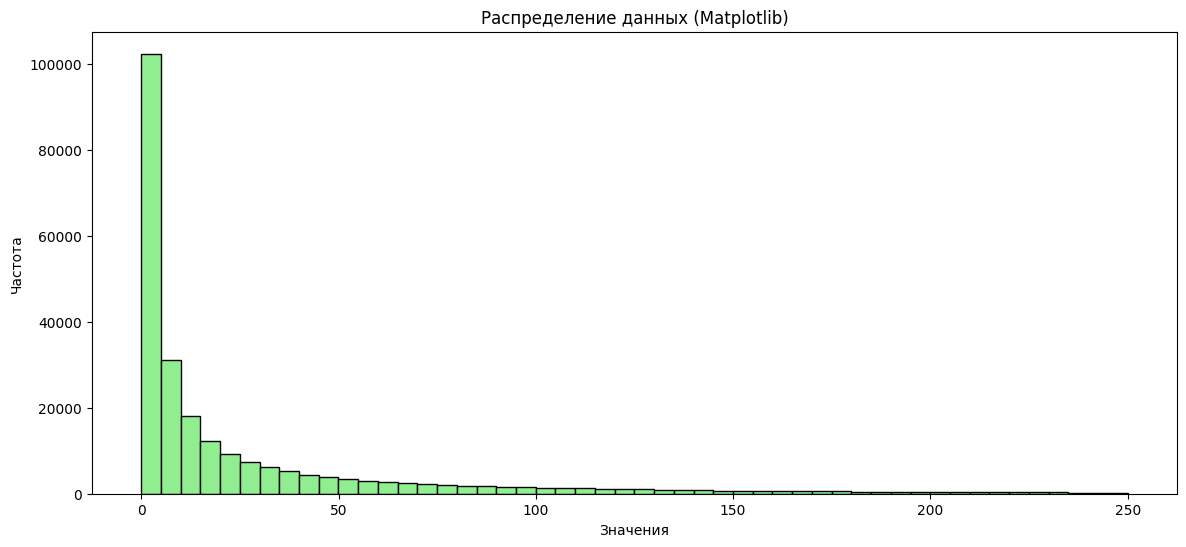

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Строим график распределения
plt.figure(figsize=(14, 6))
plt.hist(pred_series.filter(pred_series < 250).to_numpy(), bins=50, color='lightgreen', edgecolor='black')
plt.title('Распределение данных (Matplotlib)')
plt.xlabel('Значения')
plt.ylabel('Частота')
plt.show()